<a href="https://colab.research.google.com/github/04JECC-1993951/MSSM_ago-dic-26_LMV-V4-14A/blob/main/MSSM-LMV-V4-14A-AF6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

plt.rcParams['figure.dpi'] = 110
print("Listo ✔")

Listo ✔


**AF6**

Se estudia un **manipulador robótico planar de dos grados de libertad**, formado por dos eslabones rígidos unidos por articulaciones rotacionales, como se muestra en la figura. El primer eslabón está articulado a la base, que se toma como origen del sistema de referencia, y el segundo eslabón está articulado al extremo del primero. La gravedad actúa en la dirección $-y$.

**Datos del sistema.** Cada eslabón $i$ tiene masa $m_i$, longitud $l_i$ e inercia $I_i$ respecto a su centro de gravedad (CG), ubicado a una distancia $l_{ci}$ de su articulación. En cada articulación actúa un par $\tau_i$ generado por un motor.

**Coordenadas generalizadas.** La configuración del brazo queda definida por dos ángulos:

- $q_1$: ángulo del eslabón 1, medido desde la vertical hacia abajo ($-y$), positivo en sentido antihorario.
- $q_2$: ángulo del eslabón 2, medido respecto al eslabón 1 (ángulo relativo).

**Objetivo.** Obtener el modelo dinámico del manipulador mediante las ecuaciones de Euler–Lagrange, en la forma

### Matriz de inercia $M(q)$

$$
M(q)=\begin{bmatrix}
m_1 l_{c1}^2 + I_1 + m_2\left(l_1^2 + l_{c2}^2 + 2\,l_1 l_{c2}\cos q_2\right) + I_2
&
m_2\left(l_{c2}^2 + l_1 l_{c2}\cos q_2\right) + I_2
\\[8pt]
m_2\left(l_{c2}^2 + l_1 l_{c2}\cos q_2\right) + I_2
&
m_2 l_{c2}^2 + I_2
\end{bmatrix}
$$

### Matriz de Coriolis y centrífuga $C(q,\dot q)$

$$
C(q,\dot q)=\begin{bmatrix}
-m_2 l_1 l_{c2}\sin q_2\,\dot q_2
&
-m_2 l_1 l_{c2}\sin q_2\,(\dot q_1+\dot q_2)
\\[8pt]
m_2 l_1 l_{c2}\sin q_2\,\dot q_1
&
0
\end{bmatrix}
$$

### Vector de gravedad $G(q)$

$$
G(q)=\begin{bmatrix}
(m_1 l_{c1} + m_2 l_1)\,g\sin q_1 + m_2\, g\, l_{c2}\sin(q_1+q_2)
\\[8pt]
m_2\, g\, l_{c2}\sin(q_1+q_2)
\end{bmatrix}
$$

### Ecuaciones de movimiento

$$
\begin{aligned}
\tau_1 ={}& \Big[m_1 l_{c1}^2 + I_1 + m_2\big(l_1^2 + l_{c2}^2 + 2\,l_1 l_{c2}\cos q_2\big) + I_2\Big]\ddot q_1
+ \Big[m_2\big(l_{c2}^2 + l_1 l_{c2}\cos q_2\big) + I_2\Big]\ddot q_2 \\
&- 2\,m_2 l_1 l_{c2}\sin q_2\,\dot q_1\dot q_2
- m_2 l_1 l_{c2}\sin q_2\,\dot q_2^2 \\
&+ (m_1 l_{c1} + m_2 l_1)\,g\sin q_1
+ m_2\, g\, l_{c2}\sin(q_1+q_2)
\end{aligned}
$$

$$
\begin{aligned}
\tau_2 ={}& \Big[m_2\big(l_{c2}^2 + l_1 l_{c2}\cos q_2\big) + I_2\Big]\ddot q_1
+ \Big[m_2 l_{c2}^2 + I_2\Big]\ddot q_2 \\
&+ m_2 l_1 l_{c2}\sin q_2\,\dot q_1^2
+ m_2\, g\, l_{c2}\sin(q_1+q_2)
\end{aligned}
$$

### Aceleraciones

$$
\ddot q = M(q)^{-1}\left[\tau - C(q,\dot q)\,\dot q - G(q)\right]
$$

**Casos de simulación.**

| Caso | Condiciones iniciales | Pares aplicados |  |
|---|---|---|---|
| a) | $q_1(0)=60^\circ$, $q_2(0)=0^\circ$, velocidades nulas | $\tau_1=\tau_2=0$ (sin torques externos) |
| b) | $q_1(0)=0^\circ$, $q_2(0)=0^\circ$, velocidades nulas | $\tau_1=10\ \mathrm{N\,m}$, $\tau_2=1\ \mathrm{N\,m}$ (constantes) |

In [ ]:
# ===== Parámetros del manipulador (AJUSTAR con los datos del enunciado) =====
m1, m2   = 1.0, 1.0          # masas de los eslabones [kg]
l1, l2   = 0.5, 0.4          # longitudes de los eslabones [m]
lc1, lc2 = l1/2, l2/2        # distancia de la articulación al CG de cada eslabón [m]
I1 = m1 * l1**2 / 12         # inercia del eslabón 1 respecto a su CG [kg·m²]  (barra uniforme)
I2 = m2 * l2**2 / 12         # inercia del eslabón 2 respecto a su CG [kg·m²]  (barra uniforme)
g  = 9.81                    # gravedad [m/s²]

# ===== Pares aplicados en las articulaciones: tau(t) = [tau1, tau2] =====
# Caso a): sin torques externos, el brazo se mueve libremente por la gravedad
def par_a(t):
    return np.array([0.0, 0.0])      # [N·m]

# Caso b): torques constantes
def par_b(t):
    return np.array([10.0, 1.0])     # [N·m]  tau1 = 10, tau2 = 1

In [ ]:
def modelo_manipulador(x, t, m1, m2, l1, lc1, lc2, I1, I2, g, par):
    q1, q2, qd1, qd2 = x                          # estado: [q1, q2, q1_punto, q2_punto]
    qd = np.array([qd1, qd2])                     # vector de velocidades articulares

    # Matriz de inercia M(q)
    M11 = m1*lc1**2 + m2*(l1**2 + lc2**2 + 2*l1*lc2*np.cos(q2)) + I1 + I2
    M12 = m2*(lc2**2 + l1*lc2*np.cos(q2)) + I2
    M22 = m2*lc2**2 + I2
    Mq = np.array([[M11, M12],
                   [M12, M22]])

    # Matriz de Coriolis y fuerzas centrífugas C(q, q_punto)
    h = m2 * l1 * lc2 * np.sin(q2)                # factor que se repite en C
    Cq = np.array([[-h * qd2, -h * (qd1 + qd2)],
                   [ h * qd1,  0.0            ]])

    # Vector de gravedad G(q)  (q1 medido desde la vertical hacia abajo, -y)
    G1 = (m1*lc1 + m2*l1) * g * np.sin(q1) + m2 * lc2 * g * np.sin(q1 + q2)
    G2 = m2 * lc2 * g * np.sin(q1 + q2)
    Gq = np.array([G1, G2])

    tau = par(t)                                  # pares aplicados en el instante t

    # Despejamos las aceleraciones:  M · q_dosPuntos = tau − C·q_punto − G
    qdd = np.linalg.solve(Mq, tau - Cq @ qd - Gq)

    return [qd1, qd2, qdd[0], qdd[1]]             # [ q1_punto, q2_punto, q1_dosPuntos, q2_dosPuntos ]

In [ ]:
# ===== Funciones auxiliares: energías y posiciones =====
def energias(q1, q2, qd1, qd2):
    M11 = m1*lc1**2 + m2*(l1**2 + lc2**2 + 2*l1*lc2*np.cos(q2)) + I1 + I2
    M12 = m2*(lc2**2 + l1*lc2*np.cos(q2)) + I2
    M22 = m2*lc2**2 + I2
    T = 0.5*M11*qd1**2 + M12*qd1*qd2 + 0.5*M22*qd2**2           # energía cinética
    U = -(m1*lc1 + m2*l1)*g*np.cos(q1) - m2*lc2*g*np.cos(q1 + q2)  # energía potencial
    return T, U

def posiciones(q1, q2):
    x_cod, y_cod = l1*np.sin(q1), -l1*np.cos(q1)                        # codo
    x_ef,  y_ef  = x_cod + l2*np.sin(q1+q2), y_cod - l2*np.cos(q1+q2)   # extremo
    return x_cod, y_cod, x_ef, y_ef

In [ ]:
# ===== CASO a): q1(0) = 60°, q2(0) = 0°, sin torques =====
# Condiciones iniciales: [q1(0), q2(0), q1_punto(0), q2_punto(0)]  (ángulos en radianes)
x0_a = [np.radians(60), np.radians(0), 0.0, 0.0]

# ===== Tiempo: de 0 a 5 s (AJUSTAR si el enunciado indica otro) =====
t = np.linspace(0, 5, 1000)

# ===== Resolver (tolerancias estrictas para conservar bien la energía) =====
sol_a = odeint(modelo_manipulador, x0_a, t,
               args=(m1, m2, l1, lc1, lc2, I1, I2, g, par_a),
               rtol=1e-10, atol=1e-10)

q1_a  = sol_a[:, 0]       # ángulo de la articulación 1
q2_a  = sol_a[:, 1]       # ángulo de la articulación 2 (relativo al eslabón 1)
qd1_a = sol_a[:, 2]       # velocidad articular 1
qd2_a = sol_a[:, 3]       # velocidad articular 2

In [ ]:
# ===== CASO b): condiciones iniciales nulas, tau1 = 10 N·m, tau2 = 1 N·m =====
x0_b = [0.0, 0.0, 0.0, 0.0]

sol_b = odeint(modelo_manipulador, x0_b, t,
               args=(m1, m2, l1, lc1, lc2, I1, I2, g, par_b),
               rtol=1e-10, atol=1e-10)

q1_b  = sol_b[:, 0]
q2_b  = sol_b[:, 1]
qd1_b = sol_b[:, 2]
qd2_b = sol_b[:, 3]

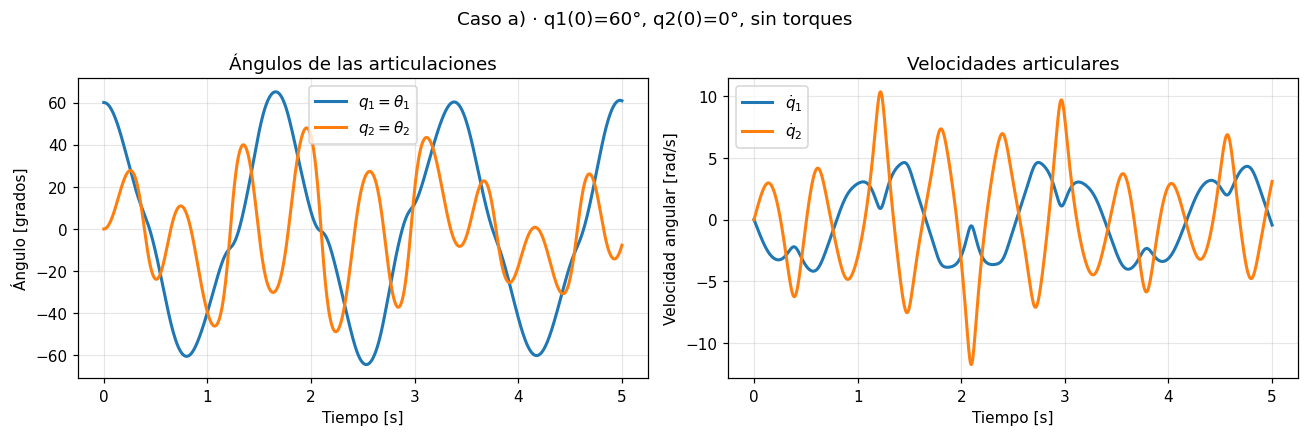

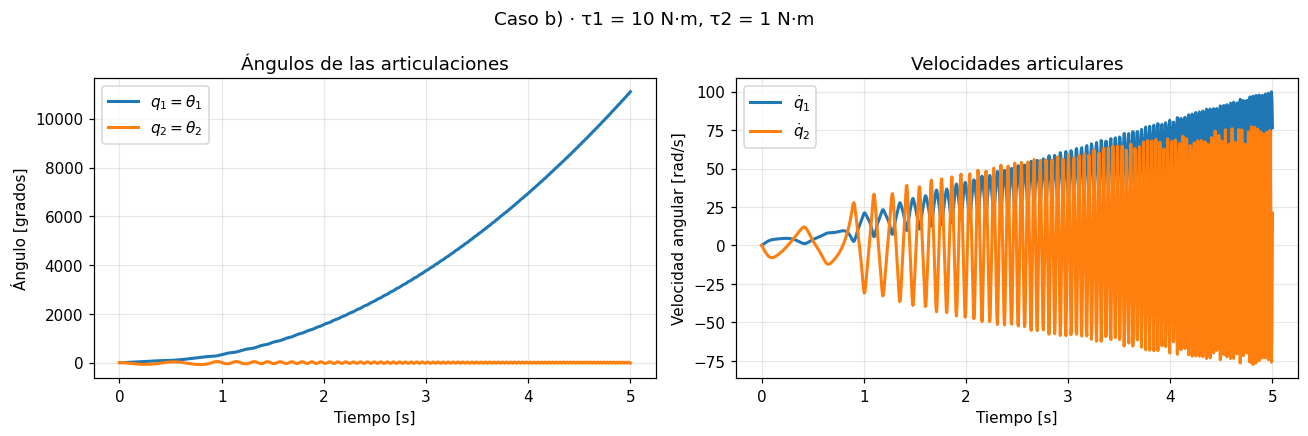

In [ ]:
def graficar(t, q1, q2, qd1, qd2, titulo):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(t, np.degrees(q1), lw=2, label=r'$q_1 = \theta_1$')
    ax1.plot(t, np.degrees(q2), lw=2, label=r'$q_2 = \theta_2$')
    ax1.set_xlabel('Tiempo [s]'); ax1.set_ylabel('Ángulo [grados]')
    ax1.set_title('Ángulos de las articulaciones'); ax1.grid(alpha=0.3); ax1.legend()

    ax2.plot(t, qd1, lw=2, label=r'$\dot{q}_1$')
    ax2.plot(t, qd2, lw=2, label=r'$\dot{q}_2$')
    ax2.set_xlabel('Tiempo [s]'); ax2.set_ylabel('Velocidad angular [rad/s]')
    ax2.set_title('Velocidades articulares'); ax2.grid(alpha=0.3); ax2.legend()

    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()

graficar(t, q1_a, q2_a, qd1_a, qd2_a, 'Caso a) · q1(0)=60°, q2(0)=0°, sin torques')
graficar(t, q1_b, q2_b, qd1_b, qd2_b, 'Caso b) · τ1 = 10 N·m, τ2 = 1 N·m')

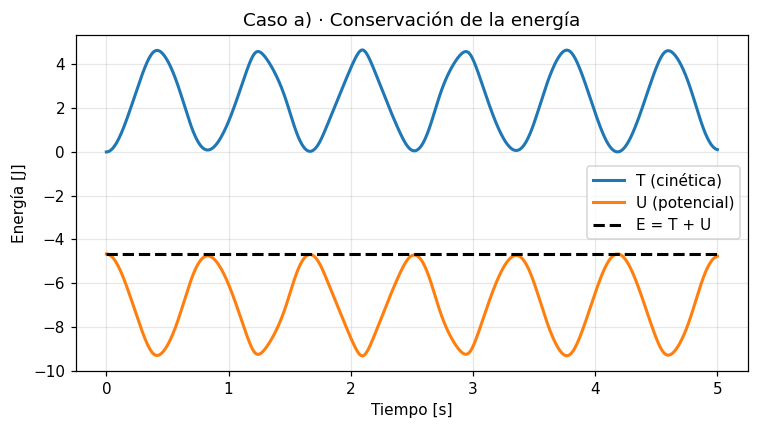

Variación máxima de E: 1.43e-09 J


In [ ]:
# ===== Verificación del modelo: energía en el Caso a) (tau = 0, sin fricción) =====
Ta, Ua = energias(q1_a, q2_a, qd1_a, qd2_a)

plt.figure(figsize=(7, 4))
plt.plot(t, Ta, lw=2, label='T (cinética)')
plt.plot(t, Ua, lw=2, label='U (potencial)')
plt.plot(t, Ta + Ua, 'k--', lw=2, label='E = T + U')
plt.xlabel('Tiempo [s]'); plt.ylabel('Energía [J]')
plt.title('Caso a) · Conservación de la energía')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

print(f"Variación máxima de E: {np.max(np.abs((Ta+Ua) - (Ta+Ua)[0])):.2e} J")

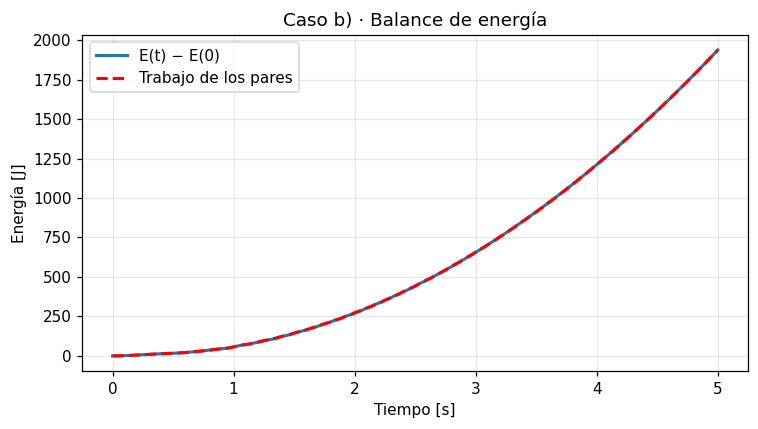

In [ ]:
# ===== Caso b): la energía NO se conserva (los motores inyectan energía) =====
# Comprobación: E(t) - E(0) debe igualar el trabajo de los pares W = ∫(tau1*qd1 + tau2*qd2) dt
Tb, Ub = energias(q1_b, q2_b, qd1_b, qd2_b)
Eb = Tb + Ub

tau_b = par_b(0)
potencia = tau_b[0]*qd1_b + tau_b[1]*qd2_b
trabajo = np.concatenate([[0], np.cumsum(0.5*(potencia[1:] + potencia[:-1])*np.diff(t))])  # regla del trapecio

plt.figure(figsize=(7, 4))
plt.plot(t, Eb - Eb[0], lw=2, label='E(t) − E(0)')
plt.plot(t, trabajo, 'r--', lw=2, label='Trabajo de los pares')
plt.xlabel('Tiempo [s]'); plt.ylabel('Energía [J]')
plt.title('Caso b) · Balance de energía')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

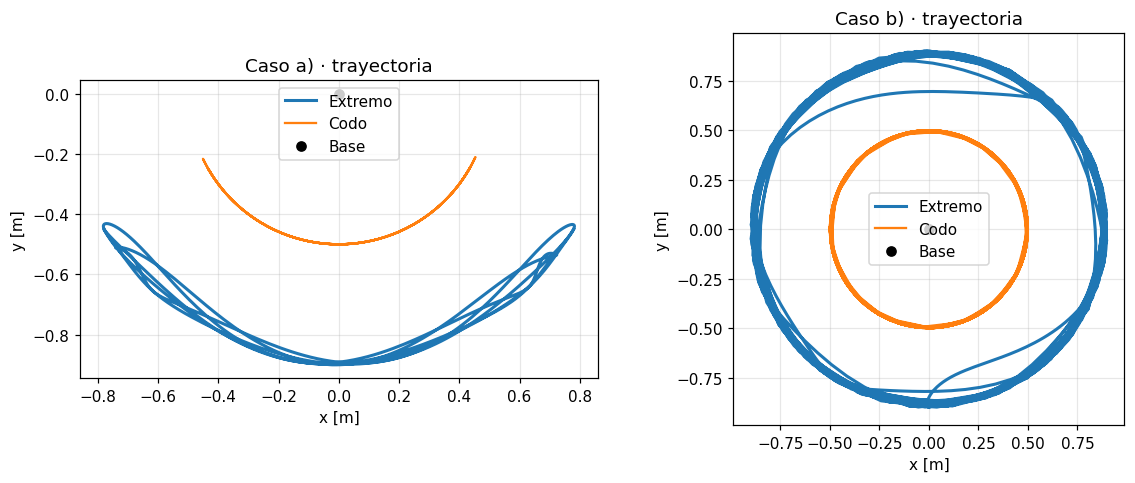

In [ ]:
# ===== Trayectoria del codo y del extremo en el plano x-y =====
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (q1, q2), tit in zip([ax1, ax2], [(q1_a, q2_a), (q1_b, q2_b)], ['Caso a)', 'Caso b)']):
    xc, yc, xe, ye = posiciones(q1, q2)
    ax.plot(xe, ye, lw=2, label='Extremo')
    ax.plot(xc, yc, lw=1.5, label='Codo')
    ax.plot(0, 0, 'ko', label='Base')
    ax.set_aspect('equal'); ax.grid(alpha=0.3); ax.legend()
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_title(f'{tit} · trayectoria')
plt.tight_layout(); plt.show()